In [58]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

In [59]:
df = pd.read_csv("mpg.csv")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [61]:
df = df.dropna(subset=["horsepower"])

In [62]:
df["horsepower"].value_counts().sum()

np.int64(392)

<Axes: xlabel='horsepower', ylabel='mpg'>

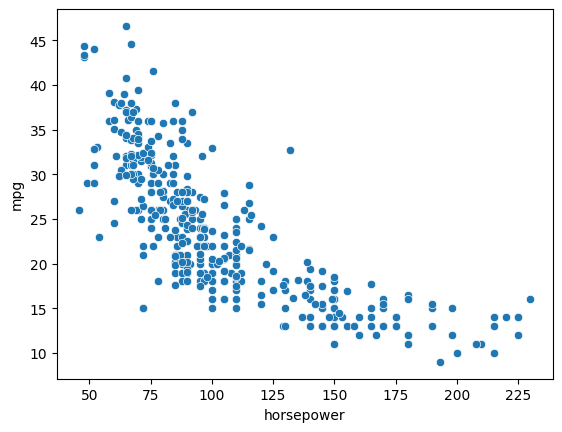

In [63]:
sns.scatterplot(data=df, x = "horsepower", y = "mpg")

In [64]:
X = df[["horsepower"]]
y = df[["mpg"]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [65]:
lin_reg = LinearRegression()
lin_reg.fit(X_train,y_train)
y_pred = lin_reg.predict(X_test)


In [66]:
R2 = r2_score(y_test, y_pred)
print("R2 Score:",R2)
MSE = mean_squared_error(y_test, y_pred)
print("MSE:",MSE)


R2 Score: 0.5659681822256185
MSE: 22.153237123863413


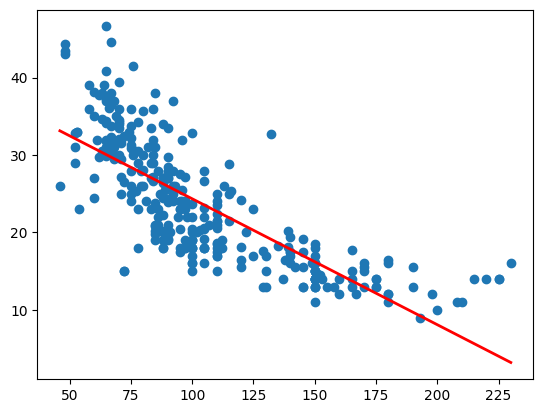

In [67]:
plt.scatter(X_train, y=y_train)
x_range = pd.DataFrame({"horsepower": np.linspace(X["horsepower"].min(), X["horsepower"].max(), 300)})
plt.plot(x_range, lin_reg.predict(x_range), color="red", linewidth=2, label="Straight line")

# With Polynomial Features

In [68]:
sample = X_train.head(3)
poly = PolynomialFeatures(degree=3, include_bias=False)
sample_poly = poly.fit_transform(sample)
print(sample_poly.shape)

pd.DataFrame(sample_poly, columns=poly.get_feature_names_out(), index=sample.index)


(3, 3)


,horsepower,horsepower^2,horsepower^3
260,110.0,12100.0,1331000.0
184,92.0,8464.0,778688.0
174,97.0,9409.0,912673.0


In [69]:
def make_poly_model(degree):
    return Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("linreg", LinearRegression()),
    ])

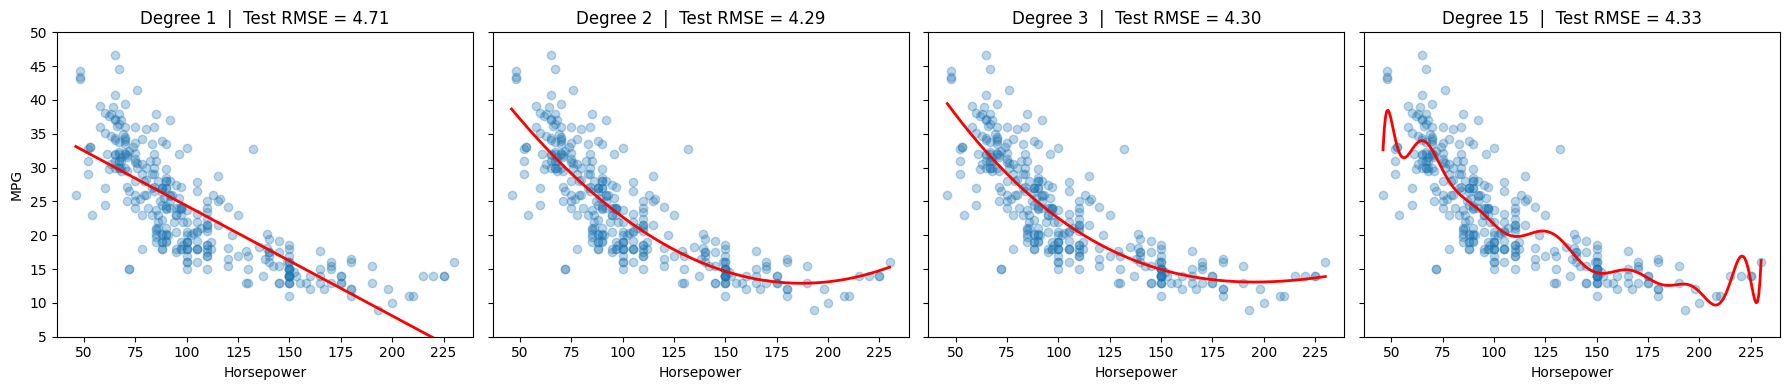

In [70]:
degree_to_show = [1,2,3,15]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, d in zip(axes,degree_to_show):
    mod = make_poly_model(d)
    mod.fit(X_train, y_train)
    test_rmse = np.sqrt(mean_squared_error(y_test, mod.predict(X_test)))

    ax.scatter(X_train, y_train, alpha=0.3)
    ax.plot(x_range, mod.predict(x_range), color="red", linewidth=2)
    ax.set_title(f"Degree {d}  |  Test RMSE = {test_rmse:.2f}")
    ax.set_xlabel("Horsepower")
    ax.set_ylim(5, 50)
axes[0].set_ylabel("MPG")
plt.tight_layout()
plt.show()

In [ ]:
pipeline = make_poly_model(degree=1)

param_grid = {
    "poly__degree": list(range(1, 11))
}

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv = 10,
    scoring="neg_root_mean_squared_error"
)

grid.fit(X_train, y_train)
print("Best degree :", grid.best_params_["poly__degree"])
print("Best CV RMSE:", round(-grid.best_score_, 3))

Best degree : 2
Best CV RMSE: 4.324


In [72]:
results = pd.DataFrame({
    "degree": grid.cv_results_["param_poly__degree"],
    "cv_rmse": -grid.cv_results_["mean_test_score"],
    "std_across_folds": grid.cv_results_["std_test_score"],
}).round(3)
results

,degree,cv_rmse,std_across_folds
0,1,4.911,0.735
1,2,4.324,0.833
2,3,4.333,0.844
3,4,4.367,0.824
4,5,4.343,0.807
5,6,4.352,0.830
6,7,4.382,0.845
7,8,4.418,0.862
8,9,4.431,0.873
9,10,4.560,0.970


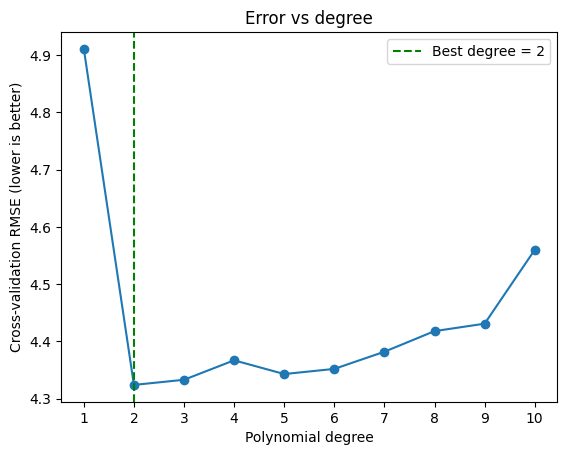

In [73]:
plt.plot(results["degree"], results["cv_rmse"], marker="o")
best_d = grid.best_params_["poly__degree"]
plt.axvline(best_d, color="green", linestyle="--", label=f"Best degree = {best_d}")
plt.xlabel("Polynomial degree")
plt.ylabel("Cross-validation RMSE (lower is better)")
plt.title("Error vs degree")
plt.xticks(results["degree"])
plt.legend()
plt.show()

In [74]:
best_model = grid.best_estimator_

y_pred_best = best_model.predict(X_test)
print(f"Best model (degree {best_d}) on the test set")
print("  R2 score :", round(r2_score(y_test, y_pred_best), 3))
print("  RMSE     :", round(np.sqrt(mean_squared_error(y_test, y_pred_best)), 3))

Best model (degree 2) on the test set
  R2 score : 0.639
  RMSE     : 4.291
